In [ ]:

import random
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

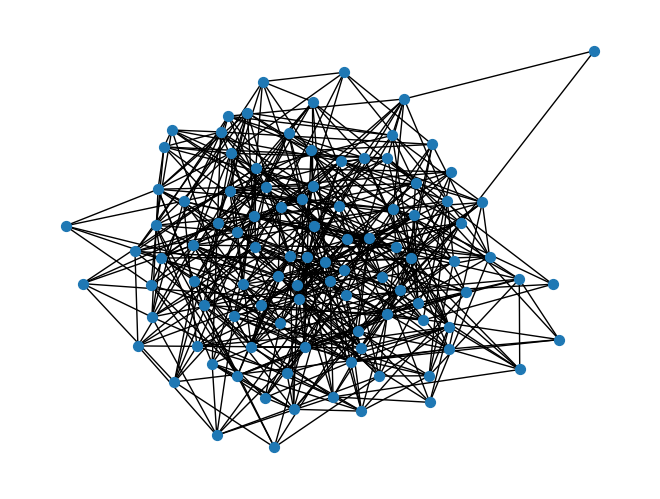

In [ ]:
n = 100
p = 0.1

G = nx.erdos_renyi_graph(n, p)

nx.draw(G, node_size=50, with_labels=False)
plt.show()


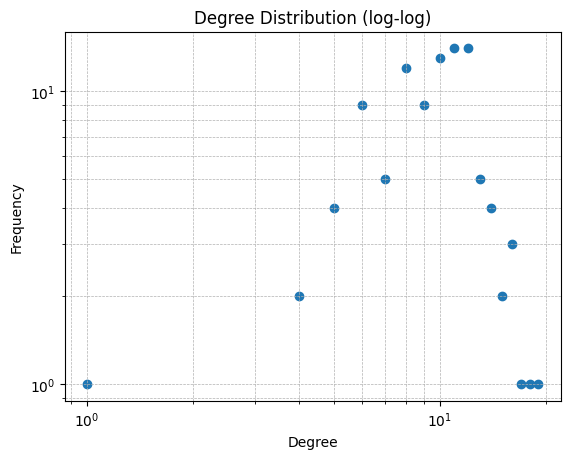

In [ ]:
degree_count = {}
for d in degree_sequence:
    if d == 0:
        continue
    if d in degree_count:
        degree_count[d] += 1
    else:
        degree_count[d] = 1

degrees = sorted(degree_count.keys())
frequency = [degree_count[d] for d in degrees]

plt.scatter(degrees, frequency)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Degree")
plt.ylabel("Frequency")
plt.title("Degree Distribution (log-log)")
plt.grid(True, which="both", ls="--", lw=0.5)
plt.show()

the degree distribution is peaked around ~10 and drops off rapidly; on a log log plot it does not form an approximately straight-line tail (as a power law/heavy tail would).

In [ ]:
nodes = list(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, dtype=int)

ones = np.ones(len(nodes)) #Get vector of all "1"

d_matrix = A @ ones

d_nx = np.array([G.degree(u) for u in nodes])

print("Degrees from matrix:", d_matrix)
print("Degrees from NetworkX:", d_nx)
print("Verification (d = A1):", np.array_equal(d_matrix, d_nx))

Degrees from matrix: [14. 11.  8. 12.  9.  8.  9.  9. 12.  7.  9. 11. 16. 11.  8.  5. 10.  7.
  9.  6.  8. 12. 14. 14.  7. 13. 15. 13. 11.  9.  7. 11. 10. 12. 15.  6.
  8.  4.  5. 10. 13. 11. 11. 10. 11.  8. 13. 10.  6.  2. 12. 14. 17. 13.
 12. 11. 14. 10. 11.  8. 12.  7.  6. 10. 12. 11. 11. 10. 10.  9.  8. 14.
 13. 11.  9. 10. 14.  9.  8. 10.  9. 11. 14. 10.  8. 14. 10. 13.  9. 13.
 11. 11.  8. 10. 11. 13. 16.  9. 11.  9.]
Degrees from NetworkX: [14 11  8 12  9  8  9  9 12  7  9 11 16 11  8  5 10  7  9  6  8 12 14 14
  7 13 15 13 11  9  7 11 10 12 15  6  8  4  5 10 13 11 11 10 11  8 13 10
  6  2 12 14 17 13 12 11 14 10 11  8 12  7  6 10 12 11 11 10 10  9  8 14
 13 11  9 10 14  9  8 10  9 11 14 10  8 14 10 13  9 13 11 11  8 10 11 13
 16  9 11  9]
Verification (d = A1): True


In [ ]:
m_nx = G.number_of_edges()
print(m_nx)
m_from_degrees = int(d_nx.sum() / 2)
print(m_from_degrees)

518
518


In [ ]:
avg_deg_netx = d_nx.mean()
print(avg_deg_netx)
avg_degree_formula = 2 * m_nx / n
print(avg_degree_formula)

10.36
10.36
